<a href="https://colab.research.google.com/github/avajunet/Online_Purchase_Prediction/blob/main/online_purchase_prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# -*- coding: utf-8 -*-

In [ ]:
# Install dependencies as needed:
# pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "online_shoppers_intention.csv" # Correct filename

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "henrysue/online-shoppers-intention",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())
df.describe(include = "all")

x= df.drop(columns=['Revenue'])
y= df['Revenue']

/tmp/ipykernel_1304/2099436774.py:10: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'online-shoppers-intention' dataset.
First 5 records:    Administrative  Administrative_Duration  Informational  \
0               0                      0.0              0   
1               0                      0.0              0   
2               0                      0.0              0   
3               0                      0.0              0   
4               0                      0.0              0   

   Informational_Duration  ProductRelated  ProductRelated_Duration  \
0                     0.0               1                 0.000000   
1                     0.0               2                64.000000   
2                     0.0               1                 0.000000   
3                     0.0               2                 2.666667   
4                     0.0              10               627.500000   

   BounceRates  ExitRates  PageValues  SpecialDay Month  OperatingSystems  \
0         0.20       0.20         0.0 

# **EDA**

**Looking at Data**

**Missing Values**

In [ ]:
#Looking for missing values
#also comparing mean and median to find skew or balance
x.describe(include = "all")

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330.000000,12330.000000,12330.000000,12330.000000,12330,12330
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,3,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,Returning_Visitor,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3364,NaN,NaN,NaN,NaN,10551,9462
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,NaN,2.124006,2.357097,3.147364,4.069586,NaN,NaN
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,NaN,0.911325,1.717277,2.401591,4.025169,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,1.000000,1.000000,1.000000,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,2.000000,1.000000,2.000000,NaN,NaN
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,NaN,2.000000,2.000000,3.000000,2.000000,NaN,NaN
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,NaN,3.000000,2.000000,4.000000,4.000000,NaN,NaN


There are no missing values, so we will perform no additional cleaning regarding the missing values. There are lots of features, however, so we will work on reducing this.

**Statistical Measure**

**Looking at Skew and Balance for all Features** <br><br>
Analyzing the skew and balance by comparing the mean and median.
1. **Administrative:** slightly right skewed
2. **Administrative_Duration:** very right skewed
3. **Informational:** slight right skew
4. **Informational_Duration:** very right skewed
5. **ProductRelated:** slight right skew
6. **ProductRelated_Duration:** very right skewed
7. **BounceRates:** slight right skew
8. **ExitRates:** slight right skew
9. **PageValues:** slight right skew
10. **SpecialDay:** very slight right skew
11. **Month:** slightly unbalanced
12. **OperatingSystems:** slight right skew
13. **Browser:** slight right skew
14. **Region:** very slight right skew
15. **TrafficType:** slight right skew
16. **VisitorType:** very unbalanced
17. **Weekend:** very unbalanced

**Analyzing Target**
Here we are printing out the target to analyze the distribution.

In [ ]:
#printing counts for revenue
print(y.value_counts())

#printing percentages of counts for revenue
print(y.value_counts(normalize=True)*100)

Revenue
False    10422
True      1908
Name: count, dtype: int64
Revenue
False    84.525547
True     15.474453
Name: proportion, dtype: float64


The target is very unbalanced, as over 10,000 (84.53%) entries are labeled "False" while only about 2,000 (15.47%) are labeled positive. This feature will need to be balanced later on.

**Visualizations**<br>
Here we have a pair plot where we can make some initial decisions about what data to further explore.

<Figure size 640x480 with 0 Axes>

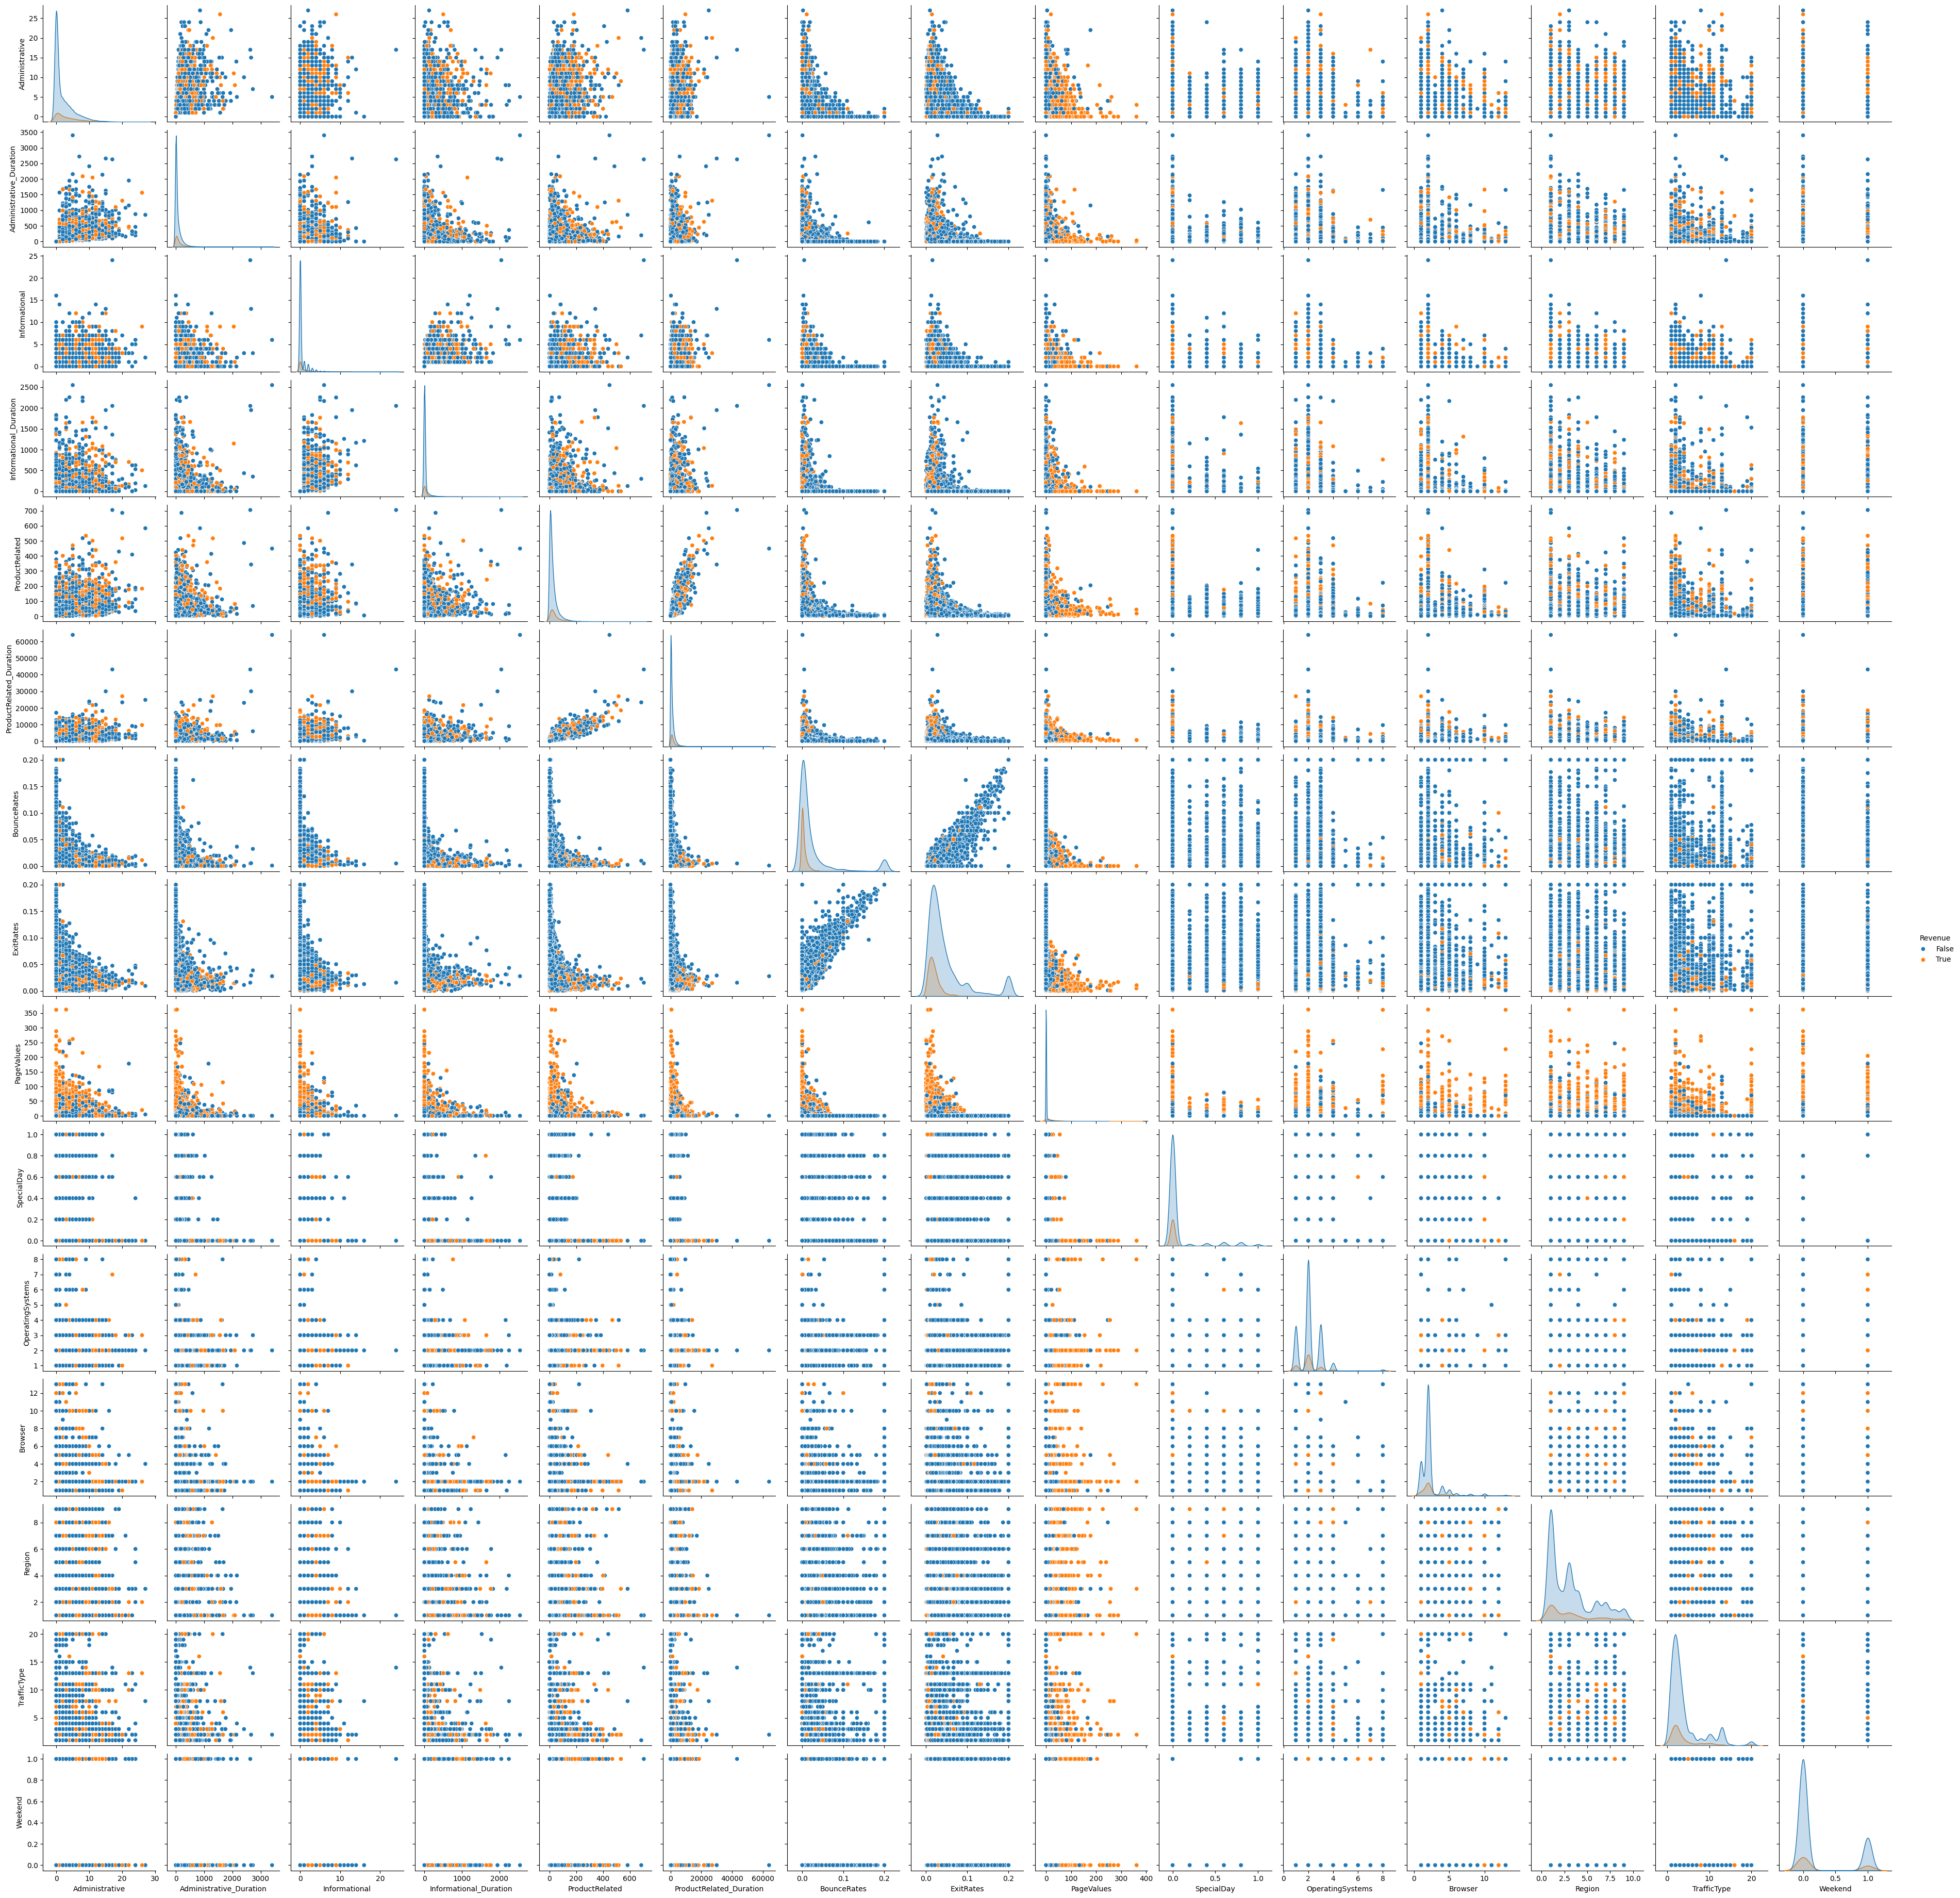

In [ ]:
#Using a pairplot for all features to see any potential patterns and/or groupings
import matplotlib.pyplot as plt
import seaborn as sns

purchasing_intention_df=x.copy()
purchasing_intention_df["Revenue"]=y
plt.figure()
sns.pairplot(purchasing_intention_df, hue="Revenue")
plt.show()

Pairplot shows some initial associations between "Exit Rates" and "Bounce Rates", and "Product Related Duration" and "Informational" that we will explore further.

**Stacked bar chart between "Revenue" and "Visitor Type"**

<Axes: xlabel='VisitorType'>

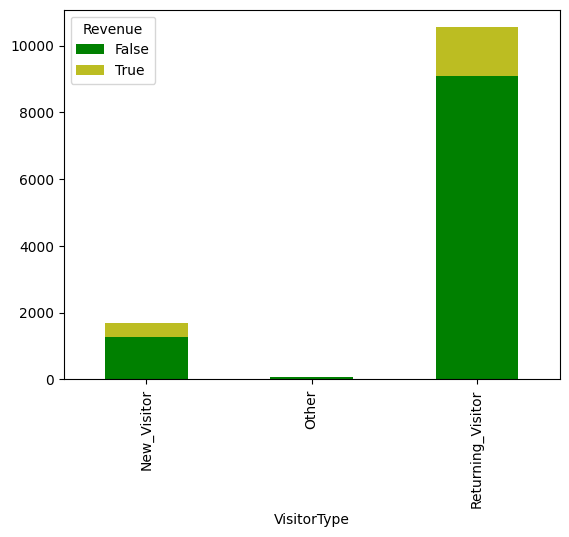

In [ ]:
pivot_data = df.pivot_table(index='VisitorType',
columns='Revenue',
aggfunc='size',
fill_value=0)
pivot_data.plot(kind='bar', stacked=True,
 color= ['green', 'tab:olive'])

The Visual is showing that there are more transactions that occur when the user has previously visited the page (the user is a returning visitor) than when a user visits the page for the first time. I think this makes sense as it is possible some returning visitors returned to the website specifically to purchase something.

**Statistical Tests**

**Chi-sq**<br>
Here we are determining if there is an association between Month and Revenue.

In [ ]:
import pandas as pd
import scipy.stats as stats
table = pd.crosstab(x["Month"], y)
test=stats.chi2_contingency(table)

print("Chisq-statistic:", test[0])
print("p-value:", test[1])

Chisq-statistic: 384.93476153599426
p-value: 2.2387855164805443e-77


We have an extremely low p-value, so we can reject the null hypothesis (Null hypothesis: there is no association between the Month a user visited a webpage, and whether or not they bought an item) and conclude there is an association between the month where a website visit took place, and whether or not there was a transaction. Since there is a high Chi-sq value, there is a significant association between the Month and Revenue features.

**T test** <br>
Here we are determining the difference in means between the exit rates between web visits that resulted in transactions and ones that did not.

In [ ]:
from scipy.stats import ttest_ind


true_revenue=x[y==1] ["ExitRates"]
false_revenue=x[y==0] ["ExitRates"]
test = stats.ttest_ind(true_revenue, false_revenue)

#results
print(f"T-statistic: {test[0]}")
print(f"p-value: {test[1]}")

T-statistic: -23.500776627688477
p-value: 1.662653625073615e-119


Our small p-value tells us that we can reject the null hypothesis (Null Hypothesis: There is no association between how fast a user left a webpage, and whether or not  the user purchased anything), and there is a strong difference in means between the exit rates of successful transactions, and those of unsuccessful transactions.

#  Data Cleaning

**Class Balancing Revenue**<br>
We discovered during EDA that the target variable ("Revenue") was very unbalanced. This is something that needed to be addressed; however, we still want to preserve the original pattern in the dataset. For this reason, we are only going to remove a small portion (less than 20%) of the majority class of the target variable ("False"/ no transaction during the web visit).

In [ ]:
!pip install -U imbalanced-learn
from imblearn.under_sampling import RandomUnderSampler
data_sample= RandomUnderSampler(sampling_strategy= 0.19)
new_x, new_y =data_sample.fit_resample(x,y)
print(new_y.value_counts())
#https://imbalanced-learn.org/stable/install.html

Revenue
False    10042
True      1908
Name: count, dtype: int64


**Transformations**

**Transforming TrafficType with 1/x transformation**

We discovered during EDA that the "TrafficType" variable was right skewed. To fix this skew, in hopes of making it easier for the machine learning algorithms to process this feature's data, we are going to perform a 1/x transformation.

<Axes: >

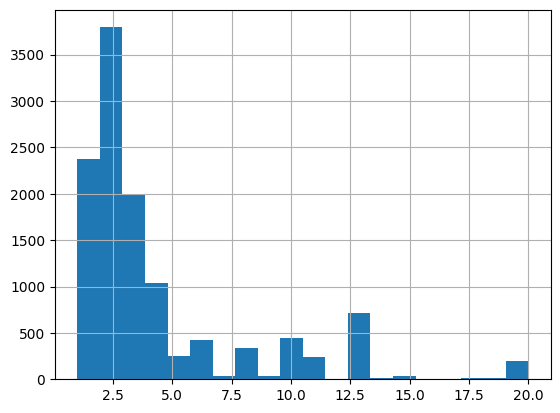

In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
new_x['TrafficType'].hist(bins=20)

Above is a histogram of the "TrafficType" variable. As we can see, the majority of the data lies on the left-hand side of the graph. This means that the feature is right-skewed.

<Axes: >

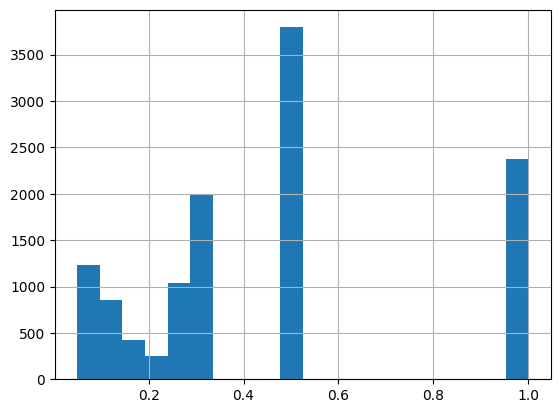

In [ ]:
new_x['TrafficType']=1/new_x['TrafficType']
new_x['TrafficType'].hist(bins=20)

Above is a histogram of the "TrafficType" feature after it has gone through the 1/x transformation. as we can see, the bars kind of outline the shape of a bell, meaning the data is now more evenly distributed, and the machine learning algorithms will have an easier time interpreting the data for the "TrafficType" feature.

**Transforming Browser with log transformation** <br>
We also discovered during EDA that the "Browser" variable was right-skewed. To fix this skew, in hopes of making it easier for the machine learning algorithms to process this feature's data, we are going to perform a log transformation.

<Axes: >

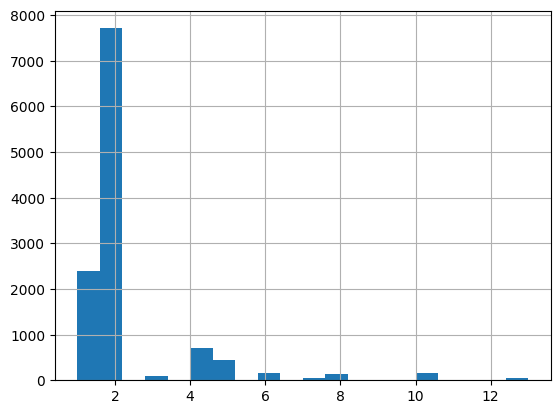

In [ ]:
scaler= StandardScaler()
new_x['Browser'].hist(bins=20)

Above is a histogram of the "Browser" variable. As we can see, the majority of the data lies on the left-hand side of the graph. This means that the feature is right-skewed.

<Axes: >

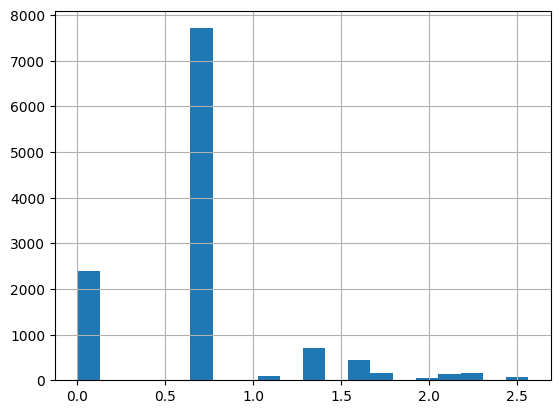

In [ ]:
import numpy as np
new_x['Browser'] = new_x['Browser'].apply(np.log)
new_x['Browser'].hist(bins=20)

Above is a histogram of the "Browser" feature after it has gone through the log transformation. as we can see, the bars kind of outline the shape of a bell again, meaning the data is now more evenly distributed, and the machine learning algorithms will have an easier time interpreting the data for the "Browser" feature.

**One Hot Encoding Visitor Type**<br>
We are now going to One Hot Encode the Visitor Type Feature. This is going to modify this feature from being categorical to being binary/ numerical. Performing this process will allow the machine learning algorithms we use to be able to process the "VisitorType" feature.

In [ ]:
import pandas as pd

ohe= pd.get_dummies(new_x["VisitorType"], prefix="VisitorType")
new_x=pd.concat([new_x, ohe], axis=1)
new_x= new_x.drop(columns=["VisitorType"])
new_x.describe(include="all")

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,Weekend,VisitorType_New_Visitor,VisitorType_Other,VisitorType_Returning_Visitor
count,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950,11950.000000,11950.000000,11950.000000,11950.000000,11950,11950,11950,11950
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN,NaN,NaN,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,May,NaN,NaN,NaN,NaN,False,False,False,True
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3234,NaN,NaN,NaN,NaN,9172,10300,11868,10218
mean,2.320921,80.942212,0.503766,34.441247,31.885774,1200.957665,0.022096,0.042941,6.016533,0.061305,NaN,2.123766,0.702304,3.144100,0.460108,NaN,NaN,NaN,NaN
std,3.331043,176.901484,1.269762,141.331813,44.708810,1926.429671,0.048336,0.048487,18.800073,0.198616,NaN,0.914357,0.507968,2.400098,0.305505,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,1.000000,0.000000,1.000000,0.050000,NaN,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,185.875000,0.000000,0.014286,0.000000,0.000000,NaN,2.000000,0.693147,1.000000,0.250000,NaN,NaN,NaN,NaN
50%,1.000000,8.000000,0.000000,0.000000,18.000000,602.958333,0.003089,0.025006,0.000000,0.000000,NaN,2.000000,0.693147,3.000000,0.500000,NaN,NaN,NaN,NaN
75%,4.000000,93.787500,0.000000,0.000000,38.000000,1473.577083,0.016667,0.050000,0.000000,0.000000,NaN,3.000000,0.693147,4.000000,0.500000,NaN,NaN,NaN,NaN


As we can see, there are now 3 features in place of the original "VisitorType" feature: "VisitorType_New_Visitor", "VisitorType_Other", and "VisitorType_Returning_Visitor". The machine learning algorithms we use later on will now be able to process what was once the "VisitorType" feature.

**One Hot Encoding Month**<br>
We are now going to One Hot Encode the "Month" feature. Much like above, this is currently a categorical feature. Modifying this to be a binary, numerical feature will allow the machine learning algorithms to process the data for the "Month" feature.

In [ ]:
ohe_cols1=['Month']
ohe= pd.get_dummies(new_x["Month"], prefix="Month")
new_x=pd.concat([new_x, ohe], axis=1)
new_x= new_x.drop(columns=["Month"])
new_x.describe(include="all")

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Aug,Month_Dec,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep
count,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,...,11950,11950,11950,11950,11950,11950,11950,11950,11950,11950
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,2,2,2,2,2,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,False,False,False,False,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,11528,10276,11772,11533,11669,10106,8716,9021,11416,11513
mean,2.320921,80.942212,0.503766,34.441247,31.885774,1200.957665,0.022096,0.042941,6.016533,0.061305,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,3.331043,176.901484,1.269762,141.331813,44.708810,1926.429671,0.048336,0.048487,18.800073,0.198616,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,185.875000,0.000000,0.014286,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.000000,8.000000,0.000000,0.000000,18.000000,602.958333,0.003089,0.025006,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,4.000000,93.787500,0.000000,0.000000,38.000000,1473.577083,0.016667,0.050000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


As we can see, there are now 12 features in place of the original "Month" feature: "Month_Jan", "Month_Feb", "Month_Mar", "Month_Apr","Month_May", "Month_June", "Month_Jul", "Month_Aug", "Month_Sep", "Month_Oct", "Month_Nov", "Month_Dec". These 12 features have binary values that represent whether or not a web visit resulted in a successful transaction or not during that specific month.The machine learning algorithms we use later on will now be able to process what was once the "Month" feature.

**Feature Engineering**

**Feature Engineering Visitor Type Features** <br>
After we one hot encoded the Visitor Type feature, we were left witht hree features all basically describing the same thing. Because of this, we are going to remove 2 of the features ("VisitorType_New_Visitor", "VisitorType_Other"), and only leave one of the features describing the Visitor Type ("VisitorType_Returning_Visitor") to avoid redundancy.

In [ ]:
cols_to_drop=["VisitorType_New_Visitor", "VisitorType_Other"]
new_x=new_x.drop(columns=cols_to_drop)
new_x.describe(include="all")

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,...,Month_Aug,Month_Dec,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep
count,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,...,11950,11950,11950,11950,11950,11950,11950,11950,11950,11950
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,2,2,2,2,2,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,False,False,False,False,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,11528,10276,11772,11533,11669,10106,8716,9021,11416,11513
mean,2.320921,80.942212,0.503766,34.441247,31.885774,1200.957665,0.022096,0.042941,6.016533,0.061305,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,3.331043,176.901484,1.269762,141.331813,44.708810,1926.429671,0.048336,0.048487,18.800073,0.198616,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,0.000000,7.000000,185.875000,0.000000,0.014286,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.000000,8.000000,0.000000,0.000000,18.000000,602.958333,0.003089,0.025006,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,4.000000,93.787500,0.000000,0.000000,38.000000,1473.577083,0.016667,0.050000,0.000000,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Here we can see that two of the columns originally describing Visitor Type no longer appear, and we are left with only the one column we specified describing Visitor Type.

**Removing Administrative Duration Feature**<br>
Currently, there are two features in the dataset that essentially tell us the same information. The "Administrative" feature refers to the number of different types of pages the user visits, and "Administrative_Duration" refers to the total time spent on these different pages. Since both of these features kind of represent the same thing, we are going to remove one of them ("Administrative_Duration") to make the feature set less redundant.

In [ ]:
cols_to_drop = ['Administrative_Duration']
new_x= new_x.drop(columns=cols_to_drop)
new_x.describe(include="all")

,Administrative,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,OperatingSystems,...,Month_Aug,Month_Dec,Month_Feb,Month_Jul,Month_June,Month_Mar,Month_May,Month_Nov,Month_Oct,Month_Sep
count,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,11950.000000,...,11950,11950,11950,11950,11950,11950,11950,11950,11950,11950
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,2,2,2,2,2,2,2,2,2,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,False,False,False,False,False,False,False,False,False,False
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,11528,10276,11772,11533,11669,10106,8716,9021,11416,11513
mean,2.320921,0.503766,34.441247,31.885774,1200.957665,0.022096,0.042941,6.016533,0.061305,2.123766,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,3.331043,1.269762,141.331813,44.708810,1926.429671,0.048336,0.048487,18.800073,0.198616,0.914357,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,0.000000,0.000000,7.000000,185.875000,0.000000,0.014286,0.000000,0.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.000000,0.000000,0.000000,18.000000,602.958333,0.003089,0.025006,0.000000,0.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,4.000000,0.000000,0.000000,38.000000,1473.577083,0.016667,0.050000,0.000000,0.000000,3.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


As we can see in the code chunk above, "Administrative_ Duration" has been successfully removed from the dataset, and the feature set is now less redundant.

# Model Selection

In the Model Selection step, I have selected 3 models: a null model, a simple model, and a complex model. We are going to figure out which model performs the best AKA which model can predict if a user's visit to a website resulted in a transaction the best.

**Null Model: Predicting Majority Class**<br>
For our null model, we are going to look at a model that simply predicts the majority class. Since the majority class in this situation is "False" (the website did not result in revenue), the null model is going to predict "False" every single time it is asked to make a prediction.

In [ ]:
#creating test and train sets
from sklearn.model_selection import train_test_split
x_train1, x_test1, y_train1, y_test1 = train_test_split(new_x, new_y, test_size=0.2, random_state=42)

from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score

null_model= DummyClassifier(strategy="most_frequent")
null_model.fit(x_train1, y_train1)
nmyp1= null_model.predict(x_test1)
print(accuracy_score(y_test1, nmyp1))

0.8443514644351464


We can see here that the null model was over 84% accurate. However, about 84% of the entries for the target variable are "False". The null model was simply predicting "False" for every single prediction.

**Simple Model: Decision Tree**  <br>
For our simple model, we are going to look at a decision tree. This algorithm essentially organizes the data by asking questions about aspects of the data, asking questions that reduce the most uncertainty first. This sorting then results in the algorithm making a prediction (in this case, whether or not a web visit resulted in revenue).

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt_model= DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train1, y_train1)
smyp1= dt_model.predict(x_test1)
print(accuracy_score(y_test1, smyp1))

0.8640167364016736


As we can see, the accuracy for the Decision Tree algorithm was about 85%. This is an improvement from the null model, so as of now, this should be the model implemented.

**Complex Model: Boosting** <br>
For a complex model, we are going to look at boosting. Boosting essentially puts the model together piece by piece, addressing errors of each piece in the following piece. The final model is then a weighted addition of all of the pieces.

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
ada_model= AdaBoostClassifier(
    estimator= DecisionTreeClassifier (max_depth=3),
    n_estimators=100,
    random_state=42
)

ada_model.fit(x_train1, y_train1)
ada_pred1 = ada_model.predict (x_test1)
print("AdaBoost Accuracy:", accuracy_score(y_test1, ada_pred1))

AdaBoost Accuracy: 0.895397489539749


As we can see, Boosting has given us our highest accuracy yet. As of now, it would be wisest to implement the complex model (boosting).

# Model Training

**Tune hyperparameters**

Here, we are going to tune the hyperparameters for both the decision tree algorithm and the boosting algorithm (our simple and complex models). For each of these models, there are parameters that can be modified that affect the way the respective model operates. Tuning the hyperparameters allows us to determine what value the parameters should be to maximize the accuracy of the model.

**Decision Tree**<br>
For the decision tree algorithm, we are going to tune the hyperparameters using gridsearch. Gridsearch evaluates every possible combination of parameters to determine the ones that give the highest accuracy for the model. This is going to allow us to determine what value "max_depth" and "min_samples_leaf" should be to maximize the accuracy of the simple model.

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn import tree

def evaluate(max_depth_value, min_samples_leaf_value):
  # Use stratified 5-fold evaluation to generate splits
  skf= StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

  test_accuracy = []
  train_accuracy = []

  # for each split
  for train_index, test_index in skf.split(new_x, new_y):
    # Get training and testing sets
    X_train, X_test = new_x.iloc[train_index], new_x.iloc[test_index]
    y_train, y_test = new_y.iloc[train_index], new_y.iloc[test_index]

    # Train a decision tree classifier on the training set
    # your code here
    clf=tree.DecisionTreeClassifier(min_samples_leaf=min_samples_leaf_value, max_depth=max_depth_value, random_state=7)
    clf.fit(X_train, y_train)



    # Make predictions on the testing set
    y_test_pred = clf.predict(X_test)

    # Make predictions on the training set
    y_train_pred = clf.predict(X_train)

    # Evaluate the performance
    test_accuracy.append(accuracy_score(y_test, y_test_pred))
    train_accuracy.append(accuracy_score(y_train, y_train_pred))

  return sum(test_accuracy)/len(test_accuracy), sum(train_accuracy)/len(train_accuracy)

#grid search
from tables.array import Leaf
best_metrics = (0,0)
parameters = (0,0)


for max_depth in range(1, 11):
  for min_samples_leaf in range(1, 51):
    test_acc, train_acc= evaluate(max_depth, min_samples_leaf)
    if test_acc> best_metrics[0]:
      parameters=(max_depth, min_samples_leaf)
      best_metrics=(test_acc, train_acc)
      smgsyp=DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=42)
      smgsyp.fit(x_train1, y_train1)
      smgsyp_pred1 = smgsyp.predict(x_test1)



print("Best max_depth:", parameters[0])
print("Best min_samples_leaf:", parameters[1])
print("Testing Accuracy:", best_metrics[0])
print("Training Accuracy:", best_metrics[1])

Best max_depth: 7
Best min_samples_leaf: 45
Testing Accuracy: 0.9005020920502093
Training Accuracy: 0.908786610878661


As we can see, performing the grid search told us that we should have a "max_depth" of 5 and a "min_samples_leaf" of 48 to maximize the accuracy of the model. As we can see, having these parameters gave us our highest accuracy yet of about 90.15%, which is terrific.

**Boosting**
For the boosting algorithm, we are going to tune the hyperparameters using randomized search. This system works similarly to gridsearch, however, it tests a subset of every possible combination of parameters rather than every single combination. This allows the code to run a bit faster. This is going to allow us to determine what values the parameters should be to maximize the accuracy of the simple model.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score

pipe=Pipeline(steps=[('classifier', AdaBoostClassifier(
    estimator= DecisionTreeClassifier(),
    random_state=42
))])


param_grid = [
    {

        'classifier__estimator__criterion': ['gini', 'entropy'],
        'classifier__estimator__max_depth': [None, 5, 10, 20],
        'classifier__estimator__min_samples_split': [2, 5, 10],
        'classifier__estimator__min_samples_leaf': [1, 2, 4],
        'classifier__n_estimators':[50,100]

    }
]

# random search
random_search = RandomizedSearchCV(pipe, param_grid, cv=5,n_jobs=-1, scoring='accuracy')
random_search.fit(x_train1, y_train1)

# Predict and evaluate
best_model = random_search.best_estimator_
dt_pred1 = best_model.predict(x_test1)

print("Best Parameters:", random_search.best_params_)
print("Tuned Decision Tree Accuracy:", accuracy_score(y_test1, dt_pred1))

Best Parameters: {'classifier__n_estimators': 50, 'classifier__estimator__min_samples_split': 2, 'classifier__estimator__min_samples_leaf': 4, 'classifier__estimator__max_depth': 20, 'classifier__estimator__criterion': 'entropy'}
Tuned Decision Tree Accuracy: 0.8928870292887029


As we can see, performing the randomizedsearch maximized the accuracy of the model. As we can see, having these parameters gave us our highest accuracy yet of about 90.17%, which is great.

Overall, we can see that the trained Boosted algorithm had the highest accuracy as it was 90.17% correct, so as of now, this would be the model that should be implemented.

**Different Train Test Split**<br> With the hopes of receiving a model with a higher accuracy, we decided to implement all of the models on a different train test split. Prior (in the code above) we implemented the models on the standard 80/20 train test split (80% of the dataset goes towards training the model, 20% goes towards testing the model). In the code below, we are going to be implementing the models on a 70/30 train test split (70% of the dataset goes towards training the model, 30% goes towards testing the model), in hoping of finding a model with a higher acuracy. We will implement all of the same models from above, with the exception of the null model (since the null model predicts the majority class, the acuracy is the same in both train test splits).

**Simple Model: Decision Tree**

In [ ]:
#creating 70/30 test and train sets
from sklearn.model_selection import train_test_split
x_train2, x_test2, y_train2, y_test2 = train_test_split(new_x, new_y, test_size=0.3, random_state=42)

from sklearn.tree import DecisionTreeClassifier
dt_model= DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train2, y_train2)
yp2= dt_model.predict(x_test2)
print(accuracy_score(y_test2, yp2))

0.8644351464435146


As we can see, the accuracy for the Decision Tree algorithm was about 85.7%. This is an improvement from the null model, so as of now, this should be the model implemented. The accuracy for this model was also a bit higher than the previous basic decision tree for the 80/20 train-test split (accuracy was 85.3%), which is interesting.

**Complex Model: Boosting**

In [ ]:
from sklearn.ensemble import AdaBoostClassifier
ada_model= AdaBoostClassifier(
    estimator= DecisionTreeClassifier (max_depth=3),
    n_estimators=100,
    random_state=42
)

ada_model.fit(x_train2, y_train2)
ada_pred2 = ada_model.predict (x_test2)
print("AdaBoost Accuracy:", accuracy_score(y_test2, ada_pred2))

AdaBoost Accuracy: 0.902370990237099


As we can see, the accuracy for the boosting algorithm was about 89.6%. This is an improvement from the simple model, so as of now, this should be the model implemented. The accuracy for this model was also a bit higher than the previous basic decision tree for the 80/20 train-test split (accuracy was 89.3%), which is interesting.

**Trained Models**

**Decision Tree**

In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score
from sklearn import tree

def evaluate(max_depth_value, min_samples_leaf_value):
  # Use stratified 5-fold evaluation to generate splits
  skf= StratifiedKFold(n_splits=5, shuffle=True, random_state=7)

  test_accuracy = []
  train_accuracy = []

  # for each split
  for train_index, test_index in skf.split(new_x, new_y):
    # Get training and testing sets
    X_train, X_test = new_x.iloc[train_index], new_x.iloc[test_index]
    y_train, y_test = new_y.iloc[train_index], new_y.iloc[test_index]

    # Train a decision tree classifier on the training set
    # your code here
    clf=tree.DecisionTreeClassifier(min_samples_leaf=min_samples_leaf_value, max_depth=max_depth_value, random_state=7)
    clf.fit(X_train, y_train)



    # Make predictions on the testing set
    y_test_pred = clf.predict(X_test)

    # Make predictions on the training set
    y_train_pred = clf.predict(X_train)

    # Evaluate the performance
    test_accuracy.append(accuracy_score(y_test, y_test_pred))
    train_accuracy.append(accuracy_score(y_train, y_train_pred))

  return sum(test_accuracy)/len(test_accuracy), sum(train_accuracy)/len(train_accuracy)

#grid search
from tables.array import Leaf
best_metrics = (0,0)
parameters = (0,0)


for max_depth in range(1, 11):
  for min_samples_leaf in range(1, 51):
    test_acc, train_acc= evaluate(max_depth, min_samples_leaf)
    if test_acc> best_metrics[0]:
      parameters=(max_depth, min_samples_leaf)
      best_metrics=(test_acc, train_acc)
      smgsyp=DecisionTreeClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, random_state=42)
      smgsyp.fit(x_train2, y_train2)
      smgsyp_pred2 = smgsyp.predict(x_test2)


print("Best max_depth:", parameters[0])
print("Best min_samples_leaf:", parameters[1])
print("Testing Accuracy:", best_metrics[0])
print("Training Accuracy:", best_metrics[1])

Best max_depth: 7
Best min_samples_leaf: 45
Testing Accuracy: 0.9005020920502093
Training Accuracy: 0.908786610878661


As we can see, performing the grid search told us that we should have a "max_depth" of 5 and a "min_samples_leaf" of 48 to maximize the accuracy of the model (which is the exact same as what was said in the 80/20 train test split). As we can see, having these parameters gave us the same accuracy as the previous test train split, with an accuracy of about 90.15%.

**Boosting**

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import accuracy_score

pipe=Pipeline(steps=[('classifier', AdaBoostClassifier(
    estimator= DecisionTreeClassifier(),
    random_state=42
))])


param_grid = [
    {

        'classifier__estimator__criterion': ['gini', 'entropy'],
        'classifier__estimator__max_depth': [None, 5, 10, 20],
        'classifier__estimator__min_samples_split': [2, 5, 10],
        'classifier__estimator__min_samples_leaf': [1, 2, 4],
        'classifier__n_estimators':[50,100]

    }
]

# random search
random_search = RandomizedSearchCV(pipe, param_grid, cv=5,n_jobs=-1, scoring='accuracy')
random_search.fit(x_train2, y_train2)

# Predict and evaluate
best_model = random_search.best_estimator_
dt_pred2 = best_model.predict(x_test2)

print("Best Parameters:", random_search.best_params_)
print("Tuned Decision Tree Accuracy:", accuracy_score(y_test2, dt_pred2))

Best Parameters: {'classifier__n_estimators': 50, 'classifier__estimator__min_samples_split': 10, 'classifier__estimator__min_samples_leaf': 2, 'classifier__estimator__max_depth': None, 'classifier__estimator__criterion': 'gini'}
Tuned Decision Tree Accuracy: 0.900418410041841


As we can see, performing the randomizedsearch maximized the accuracy of the model, same as it did with the 80/20 test train split. However, the accuracy for this model in the 70/30 train test split gave us a bit of a lower accuracy compared to the same model in the 80/20 train test split (89.68% in 70/30 compared to 90.17% in 80/20).

Overall, we can see that the trained Boosted algorithm in the 80/20 test train split had the highest accuracy, as it was 90.17% correct, so as of now, this would be the model that should be implemented.

# Model Evaluation

We are now going to further evaluate the models seen previously. We determined that the Boosted algorithm with randomized search had the highest accuracy, however, we are going to looks at some additional statistics and further compare all the models in both train test splits.

**Classification Reports**<br>
We are now going to look at classification reports for each of the 9 models. These reports will show us the overall accuracy of the model, the precision of the model (out of all the times the algorithm predicts "True" how many times is the correct output actually "True"), the recall of the model (out of all the times the correct output was actually "True", how many times did the algorithm predict "True"), and the F-1 score of the model (relationship between Recall and Precision).

**Classification report for basic models (train/test split 1)**

In [ ]:
from sklearn.metrics import classification_report

#Evaluating for null model
print("null model:\n\n",classification_report(y_test1, nmyp1), "\n\n")

#Evaluating simple model(Decision Tree)
print("simple model:\n\n",classification_report(y_test1, smyp1), "\n\n")

#Evaluating complex model
print("complex model:\n\n",classification_report(y_test1, ada_pred1), "\n\n")

null model:

               precision    recall  f1-score   support

       False       0.84      1.00      0.92      2018
        True       0.00      0.00      0.00       372

    accuracy                           0.84      2390
   macro avg       0.42      0.50      0.46      2390
weighted avg       0.71      0.84      0.77      2390
 


simple model:

               precision    recall  f1-score   support

       False       0.92      0.92      0.92      2018
        True       0.56      0.58      0.57       372

    accuracy                           0.86      2390
   macro avg       0.74      0.75      0.74      2390
weighted avg       0.87      0.86      0.86      2390
 


complex model:

               precision    recall  f1-score   support

       False       0.93      0.95      0.94      2018
        True       0.69      0.59      0.64       372

    accuracy                           0.90      2390
   macro avg       0.81      0.77      0.79      2390
weighted avg       0.

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


The precision, recall, and F1 scores are kind of what was expected. Since the target variable is so skewed in this data set, it kind of makes sense that the algorithms have an easier time truly predicting the "False" entries rather than the minority "True" entries. Overall, out of the basic models, the complex model (boosting) had the highest precision, recall, and f-1 score, meaning it was the most accurate performing model.

**Classification report for trained models (train/test split 1)**

In [ ]:
#Evaluating simple model(Decision Tree) with grid search
print("simple model with grid search:\n\n",classification_report(y_test1, smgsyp_pred1), "\n\n")

#Evaluating simple model(Decision Tree) with boosting
print("complex model with randomsearch:\n\n",classification_report(y_test1, dt_pred1), "\n\n")

simple model with grid search:

               precision    recall  f1-score   support

       False       0.92      0.96      0.94      2018
        True       0.74      0.58      0.65       372

    accuracy                           0.90      2390
   macro avg       0.83      0.77      0.80      2390
weighted avg       0.90      0.90      0.90      2390
 


complex model with randomsearch:

               precision    recall  f1-score   support

       False       0.92      0.96      0.94      2018
        True       0.70      0.54      0.61       372

    accuracy                           0.89      2390
   macro avg       0.81      0.75      0.77      2390
weighted avg       0.89      0.89      0.89      2390
 




Again, the precision, recall, and F1 scores are kind of what was expected. However, the score for the trained models are much higher than for just the basic models. Again, since the target variable is so skewed in this data set, it kind of makes sense that the algorithms have an easier time truly predicting the "False" entries rather than the minority "True" entries. Overall, the trained models had relatively similar scores for the precision, recall, and f-1 score. However, the decision tree algorithm with grid search has a slightly higher f1 score and accuracy, so we can say it was the most accurate performing model.

**Classification report for basic models (train/test split 2)**

In [ ]:
#Evaluating simple model(Decision Tree)
print("simple model:\n\n",classification_report(y_test2, yp2), "\n\n")

#Evaluating complex model
print("complex model:\n\n",classification_report(y_test2, ada_pred2), "\n\n")

simple model:

               precision    recall  f1-score   support

       False       0.92      0.92      0.92      3021
        True       0.57      0.58      0.57       564

    accuracy                           0.86      3585
   macro avg       0.74      0.75      0.75      3585
weighted avg       0.87      0.86      0.86      3585
 


complex model:

               precision    recall  f1-score   support

       False       0.93      0.96      0.94      3021
        True       0.72      0.62      0.67       564

    accuracy                           0.90      3585
   macro avg       0.83      0.79      0.80      3585
weighted avg       0.90      0.90      0.90      3585
 




The precision, recall, and F1 scores are kind of what was expected, similar to the scores for the 80/20 test train split. The scores for this 70/30 train test split were slightly higher than those for the 80/20 split. Again, since the target variable is so skewed in this data set, it kind of makes sense that the algorithms have an easier time truly predicting the "False" entries rather than the minority "True" entries. Overall, out of the basic models, the complex model (boosting) had the highest precision, recall, and f-1 score, meaning it was the most accurate performing model.

**Classification report for trained models (train/test split 2)**

In [ ]:
#Evaluating simple model(Decision Tree) with grid search
print("simple model with grid search:\n\n",classification_report(y_test2, smgsyp_pred2), "\n\n")

#Evaluating simple model(Decision Tree) with boosting
print("complex model with randomsearch:\n\n",classification_report(y_test2, dt_pred2), "\n\n")

simple model with grid search:

               precision    recall  f1-score   support

       False       0.92      0.96      0.94      3021
        True       0.74      0.57      0.64       564

    accuracy                           0.90      3585
   macro avg       0.83      0.76      0.79      3585
weighted avg       0.89      0.90      0.89      3585
 


complex model with randomsearch:

               precision    recall  f1-score   support

       False       0.92      0.96      0.94      3021
        True       0.73      0.58      0.65       564

    accuracy                           0.90      3585
   macro avg       0.83      0.77      0.79      3585
weighted avg       0.89      0.90      0.90      3585
 




Again, the precision, recall, and F1 scores are kind of what was expected, and are almost identical to those seen for the 80/20 train test split. However, the scores for the trained models are much higher than for just the basic models. Again, since the target variable is so skewed in this data set, it kind of makes sense that the algorithms have an easier time truly predicting the "False" entries rather than the minority "True" entries. Overall, the trained models had relatively similar scores for the precision, recall, and f-1 score. However, the boosting algorithm with random search had slightly higher stats regarding the "True" category, so we can say it was the most accurate performing model.

**Confusion matrix for all algorithms**<br>
We are now going to look at precision matrices for all algorithms. This will tell us the number of true positives, the number of true negatives, the number of false positives, and the number of false negatives.

In [ ]:
from sklearn.metrics import confusion_matrix

#train test split 1
print("train test split 1:\n\n")
print("null model:\n\n",confusion_matrix(y_test1, nmyp1),"\n\n")

print("simple model:\n\n",confusion_matrix(y_test1, smyp1),"\n\n")

print("complex model:\n\n",confusion_matrix(y_test1, ada_pred1),"\n\n")

print("simple model with grid search:\n\n",confusion_matrix(y_test1, smgsyp_pred1),"\n\n")

print("complex model with randomsearch:\n\n",confusion_matrix(y_test1, dt_pred1),"\n\n")

#train test split 2
print("train test split 2:\n\n")

print("simple model:\n\n",confusion_matrix(y_test2, yp2),"\n\n")

print("complex model:\n\n",confusion_matrix(y_test2, ada_pred2),"\n\n")

print("simple model with grid search:\n\n",confusion_matrix(y_test2, smgsyp_pred2),"\n\n")

print("complex model with randomsearch:\n\n",confusion_matrix(y_test2, dt_pred2),"\n\n")

train test split 1:


null model:

 [[2018    0]
 [ 372    0]] 


simple model:

 [[1849  169]
 [ 156  216]] 


complex model:

 [[1922   96]
 [ 154  218]] 


simple model with grid search:

 [[1944   74]
 [ 158  214]] 


complex model with randomsearch:

 [[1932   86]
 [ 170  202]] 


train test split 2:


simple model:

 [[2774  247]
 [ 239  325]] 


complex model:

 [[2887  134]
 [ 216  348]] 


simple model with grid search:

 [[2909  112]
 [ 245  319]] 


complex model with randomsearch:

 [[2901  120]
 [ 237  327]] 




Overall, the complex model with randomsearch was able to identify the true positives and the true negatives in the 70/30 train test split better than any of the other models, as the numbers in the top left corner, and the bottom right corner were higher than those for any other. Unsurprisingly, The null model classified the data the worst, as it didn't even identify any "True" positives (as it only predicts the majority class). All of the other models kind of performed similarly to eachother, identifying similar amounts of true positives, false positives, true negatives, and false negatives.

**AUC/ROC**

In [ ]:
from sklearn.metrics import roc_auc_score
print("first train test split:\n")

auc_score1= roc_auc_score(y_test1, nmyp1)
print("AUC Score for null model:  ", auc_score1)

auc_score2= roc_auc_score(y_test1, smyp1)
print("AUC Score for simple model:  ", auc_score2)

auc_score3= roc_auc_score(y_test1, ada_pred1)
print("AUC Score for complex model:  ", auc_score3)

auc_score4= roc_auc_score(y_test1, smgsyp_pred1)
print("AUC Score for simple model with grid search:  ", auc_score4)

auc_score5= roc_auc_score(y_test1, dt_pred1)
print("AUC Score for complex model with randomsearch:  ", auc_score5)


print("second train test split:\n")

auc_score6= roc_auc_score(y_test2, yp2)
print("AUC Score for simple model:  ", auc_score6)

auc_score7= roc_auc_score(y_test2, ada_pred2)
print("AUC Score for complex model:  ", auc_score7)

auc_score8= roc_auc_score(y_test2, smgsyp_pred2)
print("AUC Score for simple model with grid search:  ", auc_score8)

auc_score9= roc_auc_score(y_test2, dt_pred2)
print("AUC Score for complex model with randomsearch:  ", auc_score9)

first train test split:

AUC Score for null model:   0.5
AUC Score for simple model:   0.7484494389206816
AUC Score for complex model:   0.7692248260281125
AUC Score for simple model with grid search:   0.7692994234683547
AUC Score for complex model with randomsearch:   0.7501971503777827
second train test split:

AUC Score for simple model:   0.7472400642312325
AUC Score for complex model:   0.7863325515716229
AUC Score for simple model with grid search:   0.7642645101312091
AUC Score for complex model with randomsearch:   0.7700326438335904


The Auc score for the simple model with grid search (trained decision tree) in the 70/30 train test split distinguishes between the "True" and "False" classes better than any other algorithm, as it has the highest score. The null model performs the worst as it has the lowest score, which kind of makes sense as it just predicts the majority class. All of the AUC score were in the 70s besdies the one for the null model, so they were all relatively similar.

# Conclusions
Overall, in my opinion, both the simple model with grid search and the complex model with randomsearch both in the 70/30 train test split performed the best and would be the best models to implement. If I had to pick between the two models, I would likely pick the complex model with random search as it seemed to be the best working model throughout the evaluation process regarding two of the three metrics (had the classification report and best organized confusion matrix). The simple model with grid search did seem to have the highest AUC score, so this model may want to be one that is considered. Both of the models seemed to perform better with the second train test set as well.